# Section 3 Assignments: Giving Mary a Memory

Epoch Zero NLP Bootcamp · Project Hail Mary

Choose ONE assignment. Do the Basic assignment if you are on the Basic track, and the
Advanced assignment if you are on the Advanced track. Use a Google Colab notebook
(CPU is fine) and keep all your answers in one notebook.
What to submit: your completed notebook with all outputs visible. Submit through:
https://forms.gle/mBtHyLQxKTugwmc89

## BASIC ASSIGNMENT: Mission Log 3, Mary's Memory

Briefing. Mary can now read single words, but she forgets each one the moment she
moves on. Rocky's ship has started sending log messages, and Mary must decide whether
each one means SAFE (0) or DANGER (1). Order and memory matter, so you will build her
an RNN and an LSTM.

## Part A: Mary's Coding Drills

Open a fresh Colab cell for each question. Use import math , import torch , and import
torch.nn as nn . Each drill is short.


### A1. Mary's memory rule.

A tiny RNN has the rule h_t = tanh(w_x · x_t + w_h · h_(t- 1) + b) . Rocky sends the signal x = [0.5, 0, 0.5] .

Complete the function and print the hidden state after every step, rounded to 2 decimals. Then run it again with [0.5, 0, 0] .

In [1]:
# Import libraries

import math
import torch
import torch.nn as nn

torch.manual_seed(7)

In [2]:
import math
def rnn_forward(xs, w_x=1.0, w_h=1.0, b=0.0):
  h = 0.0
  history = []
  # your code here: for each x, update h with the rule above, then append h to history

  for x in xs:
        h = math.tanh(w_x * x + w_h * h + b)
        history.append(h)

  return history

print([round(h, 2) for h in rnn_forward([0.5, 0, 0.5])])
print([round(h, 2) for h in rnn_forward([0.5, 0, 0])])

[0.46, 0.43, 0.73]
[0.46, 0.43, 0.41]


## A2. The fading signal.

During BPTT, a gradient is multiplied by a fixed number at every step. Complete both functions.

In [3]:
def gradient_after(multiplier, steps):
  # your code: start with grad = 1.0 and multiply it by `multiplier` once per step
  #pass

  grad = 1.0

  for _ in range(steps):
      grad *= multiplier

  return grad

def clip(grad, max_norm=1.0):
  # your code: if grad is bigger than max_norm, scale it down to max_norm
  # (and likewise for values below -max_norm)
  #pass

  if grad > max_norm:
        return max_norm

  elif grad < -max_norm:
      return -max_norm

  return grad

print(gradient_after(0.8, 10), gradient_after(0.8, 30))
print(gradient_after(1.2, 10))
print(clip(gradient_after(1.2, 10)))

0.10737418240000006 0.0012379400392853823
6.191736422399999
1.0


## A3. Gates as volume knobs.

A gate is a sigmoid layer whose output multiplies the
memory, slot by slot.

In [4]:
import torch

memory = torch.tensor([2.0, -1.0, 0.5])
# Mary's long-term memory (3 slots)
raw_scores = torch.tensor([4.0, -4.0, 0.0])

# what the gate layer computed
# your code: gate = sigmoid of raw_scores
# your code: new_memory = memory * gate (element-wise)

# Compute gate values
gate = torch.sigmoid(raw_scores)

# Element-wise multiplication
new_memory = memory * gate

print(gate)
print(new_memory)

tensor([0.9820, 0.0180, 0.5000])
tensor([ 1.9640, -0.0180,  0.2500])


## A4. Shapes.

Build this and print the four shapes.

In [5]:
import torch.nn as nn

embedding = nn.Embedding(50, 16, padding_idx=0)

lstm = nn.LSTM(16, 32, batch_first=True)

# 16 sentences, 10 words each
x = torch.randint(1, 50, (16, 10))

# your code: emb = ..., then out, (h_n, c_n) = ...

# Embedding layer
emb = embedding(x)

# LSTM layer
out, (h_n, c_n) = lstm(emb)

# print the shapes of: emb, out, h_n, h_n[-1]

print("Embedding shape:", emb.shape)
print("Output shape:", out.shape)
print("Hidden state shape:", h_n.shape)
print("Last hidden state shape:", h_n[-1].shape)

Embedding shape: torch.Size([16, 10, 16])
Output shape: torch.Size([16, 10, 32])
Hidden state shape: torch.Size([1, 16, 32])
Last hidden state shape: torch.Size([16, 32])


## Part B: Build Mary's Memory in PyTorch

Here are Rocky's log messages (28 for training, 12 for testing). Copy the starter code into
Colab and complete the TODO s.

In [6]:
import torch
import torch.nn as nn

torch.manual_seed(7)

SAFE_TRAIN = [
    'all systems are stable and fuel is full',
    'the hull is intact and the air is clean',
    'rocky is happy and the signal is clear',
    'engines are running smoothly today',
    'oxygen levels are normal and safe',
    'the reactor is calm and cool',
    'no leaks found and pressure is steady',
    'the crew is rested and healthy',
    'astrophage tank is sealed and secure',
    'the course is correct and on track',
    'temperature is normal inside the ship',
    'everything looks good and working well',
    'the signal is strong and stable',
    'fuel levels are high and steady',
]

DANGER_TRAIN = [
    'the hull is cracked and air is leaking',
    'fuel is low and engines are failing',
    'the reactor is overheating fast',
    'oxygen is dropping and the alarm is ringing',
    'a leak was found and pressure is falling',
    'the airlock is broken and unsafe',
    'the signal is lost and sensors are failing',
    'temperature is rising and the ship is burning',
    'astrophage is leaking from the tank',
    'the course is wrong and we are drifting',
    'warning the engine has failed',
    'the hull is damaged and weak',
    'alarm the system is unstable and failing',
    'fuel is running out and time is short',
]

SAFE_TEST = [
    'the airlock is closed and safe',
    'all sensors are clear and normal',
    'repairs finished and the hull is strong',
    'the experiment worked perfectly',
    'the path ahead is clear and safe',
    'no danger detected all is well',
]

DANGER_TEST = [
    'the radiation is high and dangerous',
    'critical failure in the cooling system',
    'the crew is sick and the air is bad',
    'emergency the pressure is dropping fast',
    'the experiment failed and the tank cracked',
    'danger detected the path ahead is blocked',
]

train_data = (
    [(s, 0) for s in SAFE_TRAIN]
    + [(s, 1) for s in DANGER_TRAIN]
)

test_data = (
    [(s, 0) for s in SAFE_TEST]
    + [(s, 1) for s in DANGER_TEST]
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))
print("SAFE training samples:", len(SAFE_TRAIN))
print("DANGER training samples:", len(DANGER_TRAIN))

Training samples: 28
Testing samples: 12
SAFE training samples: 14
DANGER training samples: 14


## B1:

Complete TODO 1 and TODO 2. Print word_to_id['hull'] and encode('the hull is
cracked') and show the output.*italicized text*

In [9]:
# ---------- TODO 1: build the vocabulary (from TRAIN sentences only) ----------
# word_to_id must map '<PAD>' -> 0 and '<UNK>' -> 1, then every new word
# in train_data gets the next free number.
word_to_id = {'<PAD>': 0, '<UNK>': 1}
# your code here

for sentence, label in train_data:

    for word in sentence.split():

        if word not in word_to_id:
            word_to_id[word] = len(word_to_id)

print("Vocabulary size:", len(word_to_id))
print("ID of hull:", word_to_id['hull'])
print("Vocabulary:", word_to_id)

Vocabulary size: 91
ID of hull: 11
Vocabulary: {'<PAD>': 0, '<UNK>': 1, 'all': 2, 'systems': 3, 'are': 4, 'stable': 5, 'and': 6, 'fuel': 7, 'is': 8, 'full': 9, 'the': 10, 'hull': 11, 'intact': 12, 'air': 13, 'clean': 14, 'rocky': 15, 'happy': 16, 'signal': 17, 'clear': 18, 'engines': 19, 'running': 20, 'smoothly': 21, 'today': 22, 'oxygen': 23, 'levels': 24, 'normal': 25, 'safe': 26, 'reactor': 27, 'calm': 28, 'cool': 29, 'no': 30, 'leaks': 31, 'found': 32, 'pressure': 33, 'steady': 34, 'crew': 35, 'rested': 36, 'healthy': 37, 'astrophage': 38, 'tank': 39, 'sealed': 40, 'secure': 41, 'course': 42, 'correct': 43, 'on': 44, 'track': 45, 'temperature': 46, 'inside': 47, 'ship': 48, 'everything': 49, 'looks': 50, 'good': 51, 'working': 52, 'well': 53, 'strong': 54, 'high': 55, 'cracked': 56, 'leaking': 57, 'low': 58, 'failing': 59, 'overheating': 60, 'fast': 61, 'dropping': 62, 'alarm': 63, 'ringing': 64, 'a': 65, 'leak': 66, 'was': 67, 'falling': 68, 'airlock': 69, 'broken': 70, 'unsafe':

In [12]:
# ---------- TODO 2: turn a sentence into a list of exactly MAX_LEN numbers ----------
# Unknown words -> 1. Pad with 0s on the LEFT, so the last real word sits
# right next to the output (the LSTM's final state is then taken after a real word).

MAX_LEN = 10
def encode(sentence):
  # your code here
  # pass

  words = sentence.split()

  # Convert words into token IDs
  ids = [
      word_to_id.get(word, word_to_id['<UNK>'])
      for word in words
  ]

  # Keep the last MAX_LEN tokens
  ids = ids[-MAX_LEN:]

  # Left padding
  ids = [0] * (MAX_LEN - len(ids)) + ids

  return ids

print("ID of hull:", word_to_id['hull'])

print("Encoded sentence:",
      encode('the hull is cracked'))

ID of hull: 11
Encoded sentence: [0, 0, 0, 0, 0, 0, 10, 11, 8, 56]


## B2:

Complete TODO 3 and run the provided code. Submit a screenshot showing the loss going down, the test accuracy, and the sentence-by-sentence predictions.

In [16]:
# ---------- TODO 3: complete the model ----------
# Embedding (padding_idx=0) -> LSTM (batch_first=True) -> Linear -> 2 class scores.
# Use the LAST hidden state of the LSTM as the input to the Linear layer.

class MaryLSTM(nn.Module):
  def __init__(self, vocab_size, embed_dim=16, hidden_dim=32):
    super().__init__()
    # your code here
    self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

    self.lstm = nn.LSTM(
        embed_dim,
        hidden_dim,
        batch_first=True
    )

    self.fc = nn.Linear(hidden_dim, 2)

  def forward(self, x):
    # your code here
    # pass
    emb = self.embedding(x)

    out, (h_n, c_n) = self.lstm(emb)

    last_hidden = h_n[-1]

    logits = self.fc(last_hidden)

    return logits

In [17]:
# ---------- Provided: training and testing (do not change) ----------
X_train = torch.tensor([encode(s) for s, _ in train_data])
y_train = torch.tensor([l for _, l in train_data])
X_test = torch.tensor([encode(s) for s, _ in test_data])
y_test = torch.tensor([l for _, l in test_data])

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: torch.Size([28, 10])
y_train: torch.Size([28])
X_test: torch.Size([12, 10])
y_test: torch.Size([12])


In [18]:
torch.manual_seed(7)

model = MaryLSTM(len(word_to_id))

opt = torch.optim.Adam(model.parameters(), lr=0.01)

loss_fn = nn.CrossEntropyLoss()

for epoch in range(60):
  loss = loss_fn(model(X_train), y_train)
  opt.zero_grad()
  loss.backward()
  opt.step()
  if (epoch + 1) % 10 == 0:
    print('epoch', epoch + 1, 'loss', round(loss.item(), 4))


epoch 10 loss 0.2539
epoch 20 loss 0.0024
epoch 30 loss 0.0002
epoch 40 loss 0.0001
epoch 50 loss 0.0
epoch 60 loss 0.0


In [19]:
model.eval()
with torch.no_grad():
  preds = model(X_test).argmax(dim=1)

  print('Test accuracy:', (preds == y_test).float().mean().item())

  for (s, label), p in zip(test_data, preds.tolist()):
    print(label, p, s)
    # true label, predicted label, sentence

Test accuracy: 0.5833333134651184
0 1 the airlock is closed and safe
0 0 all sensors are clear and normal
0 1 repairs finished and the hull is strong
0 1 the experiment worked perfectly
0 0 the path ahead is clear and safe
0 0 no danger detected all is well
1 0 the radiation is high and dangerous
1 1 critical failure in the cooling system
1 0 the crew is sick and the air is bad
1 1 emergency the pressure is dropping fast
1 1 the experiment failed and the tank cracked
1 1 danger detected the path ahead is blocked


In [20]:
# Display the LSTM predictions clearly

lstm_model = model

lstm_accuracy = (
    (preds == y_test).float().mean().item()
)

label_names = {
    0: "SAFE",
    1: "DANGER"
}

print(f"LSTM Test Accuracy: {lstm_accuracy * 100:.2f}%")

print("-" * 80)

for (sentence, label), pred in zip(
    test_data, preds.tolist()
):

    print(
        f"True: {label_names[label]:7s} | "
        f"Predicted: {label_names[pred]:7s} | "
        f"{sentence}"
    )

LSTM Test Accuracy: 58.33%
--------------------------------------------------------------------------------
True: SAFE    | Predicted: DANGER  | the airlock is closed and safe
True: SAFE    | Predicted: SAFE    | all sensors are clear and normal
True: SAFE    | Predicted: DANGER  | repairs finished and the hull is strong
True: SAFE    | Predicted: DANGER  | the experiment worked perfectly
True: SAFE    | Predicted: SAFE    | the path ahead is clear and safe
True: SAFE    | Predicted: SAFE    | no danger detected all is well
True: DANGER  | Predicted: SAFE    | the radiation is high and dangerous
True: DANGER  | Predicted: DANGER  | critical failure in the cooling system
True: DANGER  | Predicted: SAFE    | the crew is sick and the air is bad
True: DANGER  | Predicted: DANGER  | emergency the pressure is dropping fast
True: DANGER  | Predicted: DANGER  | the experiment failed and the tank cracked
True: DANGER  | Predicted: DANGER  | danger detected the path ahead is blocked


B3: Copy your class, rename it MaryRNN , and swap nn.LSTM for nn.RNN . Hint: nn.RNN
returns out, h_n , with no cell state. Train it with the same loop and report the test
accuracy of both models in a small table.

In [21]:
class MaryRNN(nn.Module):

    def __init__(self, vocab_size,
                 embed_dim=16, hidden_dim=32):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            embed_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):

        emb = self.embedding(x)

        out, h_n = self.rnn(emb)

        last_hidden = h_n[-1]

        logits = self.fc(last_hidden)

        return logits

In [22]:
# Train the RNN

torch.manual_seed(7)

rnn_model = MaryRNN(len(word_to_id))

opt = torch.optim.Adam(
    rnn_model.parameters(),
    lr=0.01
)

loss_fn = nn.CrossEntropyLoss()

for epoch in range(60):

    loss = loss_fn(
        rnn_model(X_train),
        y_train
    )

    opt.zero_grad()

    loss.backward()

    opt.step()

    if (epoch + 1) % 10 == 0:

        print(
            'epoch', epoch + 1,
            'loss', round(loss.item(), 4)
        )


rnn_model.eval()

with torch.no_grad():

    rnn_preds = rnn_model(X_test).argmax(dim=1)

    rnn_accuracy = (
        (rnn_preds == y_test)
        .float().mean().item()
    )

print(f"RNN Test Accuracy: {rnn_accuracy * 100:.2f}%")

epoch 10 loss 0.0486
epoch 20 loss 0.0004
epoch 30 loss 0.0001
epoch 40 loss 0.0
epoch 50 loss 0.0
epoch 60 loss 0.0
RNN Test Accuracy: 41.67%


In [23]:
# Compare RNN and LSTM

import pandas as pd

results = pd.DataFrame({
    "Model": ["RNN", "LSTM"],
    "Embedding Dimension": [16, 16],
    "Hidden Dimension": [32, 32],
    "Training Epochs": [60, 60],
    "Test Accuracy (%)": [
        rnn_accuracy * 100,
        lstm_accuracy * 100
    ]
})

display(results.round(2))

,Model,Embedding Dimension,Hidden Dimension,Training Epochs,Test Accuracy (%)
0,RNN,16,32,60,41.67
1,LSTM,16,32,60,58.33


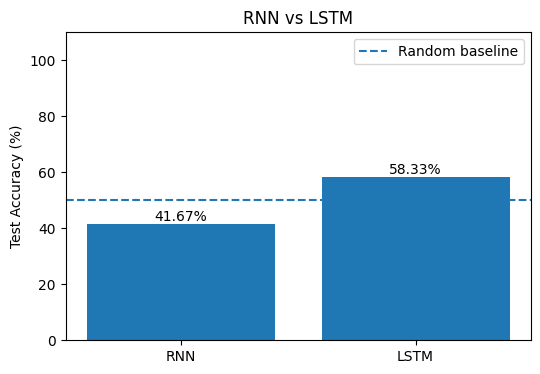

In [24]:
# Plot the test accuracy
import matplotlib.pyplot as plt

models = ["RNN", "LSTM"]

accuracies = [
    rnn_accuracy * 100,
    lstm_accuracy * 100
]

plt.figure(figsize=(6, 4))

bars = plt.bar(models, accuracies)

for bar, acc in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        acc + 1,
        f"{acc:.2f}%",
        ha="center"
    )

plt.axhline(
    50,
    linestyle="--",
    label="Random baseline"
)

plt.ylabel("Test Accuracy (%)")
plt.title("RNN vs LSTM")
plt.ylim(0, 110)
plt.legend()
plt.show()

B4: Write three new log messages of your own (one clearly SAFE, one clearly DANGER,
one tricky one), encode them with encode , and show what your LSTM predicts.

In [25]:
# Test three new log messages

new_messages = [
    "the reactor is calm and oxygen levels are normal",
    "the hull is cracked and oxygen is dropping",
    "the alarm is ringing but the reactor is cool"
]

expected_labels = [
    "SAFE",
    "DANGER",
    "TRICKY"
]

X_new = torch.tensor([
    encode(s) for s in new_messages
])

lstm_model.eval()

with torch.no_grad():

    logits = lstm_model(X_new)

    probabilities = torch.softmax(logits, dim=1)

    predictions = logits.argmax(dim=1)


for sentence, expected, pred, prob in zip(
    new_messages,
    expected_labels,
    predictions.tolist(),
    probabilities
):

    print("Message:", sentence)

    print("Expected:", expected)

    print("Prediction:", label_names[pred])

    print(f"SAFE probability: {prob[0].item():.4f}")

    print(f"DANGER probability: {prob[1].item():.4f}")

    print("-" * 60)

Message: the reactor is calm and oxygen levels are normal
Expected: SAFE
Prediction: SAFE
SAFE probability: 1.0000
DANGER probability: 0.0000
------------------------------------------------------------
Message: the hull is cracked and oxygen is dropping
Expected: DANGER
Prediction: DANGER
SAFE probability: 0.0000
DANGER probability: 1.0000
------------------------------------------------------------
Message: the alarm is ringing but the reactor is cool
Expected: TRICKY
Prediction: DANGER
SAFE probability: 0.0007
DANGER probability: 0.9993
------------------------------------------------------------


## Part C: Debrief

## C1.

Show in code why bag-of-words (Section 1) isn't enough for Mary.

In [28]:
from collections import Counter

a = 'the dog bit the man'.split()
b = 'the man bit the dog'.split()

# your code: print (1) whether Counter(a) == Counter(b)
#                  (2) whether a == b

print("Same bag-of-words:", Counter(a) == Counter(b))

print("Same word sequence:", a == b)

## Add a one-line comment saying what the two results tell you.

# Bag-of-words ignores word order, even when
# changing the order changes the sentence meaning.

# Bag-of-words represents both sentences identically because they contain the same words
# with the same frequencies. However, their meanings differ because the word order determines
# who performed the action. RNNs and LSTMs process words sequentially and can learn these differences.

Same bag-of-words: True
Same word sequence: False


## C2.

Using your trained MaryLSTM and MaryRNN models from B3, count the parameters of
only the recurrent layer (the nn.LSTM and the nn.RNN inside them) with sum(p.numel() for p in layer.parameters()) . Print both counts and their ratio. Add a one-line comment on what the ratio says about LSTMs compared to simple RNNs.

In [29]:
lstm_params = sum(
    p.numel()
    for p in lstm_model.lstm.parameters()
)

rnn_params = sum(
    p.numel()
    for p in rnn_model.rnn.parameters()
)

ratio = lstm_params / rnn_params

print("LSTM recurrent parameters:", lstm_params)

print("RNN recurrent parameters:", rnn_params)

print("Parameter ratio:", ratio)

# An LSTM has four times as many recurrent parameters
# because it uses three gates and a candidate cell state.

LSTM recurrent parameters: 6400
RNN recurrent parameters: 1600
Parameter ratio: 4.0
